In [14]:
import pandas as pd
import numpy as np
import re

# ==== 1. IMPORT DỮ LIỆU ====
# Đổi đường dẫn dưới đây thành file CSV của bạn
INPUT_PATH = "D3-CreditScore.csv"
OUTPUT_PATH = "D3-CreditScore-cleaned.csv"

df = pd.read_csv(INPUT_PATH, low_memory=False)
print("Đã đọc file:", INPUT_PATH)
print("Shape ban đầu:", df.shape)
print(df.head())

orig_shape = df.shape

# --- helper: strip garbage wrapper characters like __10000__, 8_, trailing/leading _ ---
def clean_numeric_str(s):
    if pd.isna(s):
        return np.nan
    s = str(s).strip()
    s = s.replace('_', '')  # remove stray underscores (28_, __10000__, 8_)
    s = s.replace(',', '')
    if s in ('', '-', 'nan', 'NA', 'NaN', '!@9#%8'):
        return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan

numeric_str_cols = ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment',
                     'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly',
                     'Monthly_Balance']

for c in numeric_str_cols:
    df[c] = df[c].apply(clean_numeric_str)

# Age: remove impossible values (negative, absurdly large)
df.loc[(df['Age'] < 0) | (df['Age'] > 100), 'Age'] = np.nan

# Num_of_Loan: negative codes like -100 are invalid
df.loc[df['Num_of_Loan'] < 0, 'Num_of_Loan'] = np.nan

# Num_of_Delayed_Payment: negative invalid
df.loc[df['Num_of_Delayed_Payment'] < 0, 'Num_of_Delayed_Payment'] = np.nan

# Monthly_Balance: extreme sentinel values like -333333333333333333333333333 are placeholders
df.loc[df['Monthly_Balance'].abs() > 1e6, 'Monthly_Balance'] = np.nan

# Amount_invested_monthly: 10000 sentinel (__10000__) likely placeholder for missing/extreme -> treat as NaN
df.loc[df['Amount_invested_monthly'] == 10000, 'Amount_invested_monthly'] = np.nan

# --- categorical / text cleanup ---
def clean_cat(s, placeholders):
    if pd.isna(s):
        return np.nan
    s = str(s).strip()
    if s in placeholders:
        return np.nan
    return s

df['Occupation'] = df['Occupation'].apply(lambda x: clean_cat(x, {'_______'}))
df['Credit_Mix'] = df['Credit_Mix'].apply(lambda x: clean_cat(x, {'_'}))
df['Payment_Behaviour'] = df['Payment_Behaviour'].apply(lambda x: clean_cat(x, {'!@9#%8'}))
df['Name'] = df['Name'].apply(lambda x: clean_cat(x, {''}))

# Payment_of_Min_Amount: 'NM' = Not Mentioned -> treat as missing category (keep as is, but flag)
df['Payment_of_Min_Amount'] = df['Payment_of_Min_Amount'].replace({'NM': np.nan})

# --- Credit_History_Age: "22 Years and 1 Months" -> convert to total months (numeric) ---
def parse_credit_history(s):
    if pd.isna(s):
        return np.nan
    s = str(s).strip()
    if s in ('NA', ''):
        return np.nan
    m = re.match(r'(\d+)\s*Years?\s*and\s*(\d+)\s*Months?', s)
    if m:
        years, months = int(m.group(1)), int(m.group(2))
        return years * 12 + months
    return np.nan

df['Credit_History_Age_Months'] = df['Credit_History_Age'].apply(parse_credit_history)
df.drop(columns=['Credit_History_Age'], inplace=True)

# --- SSN: garbage values like '#F%$D@*&8' -> NaN ---
def clean_ssn(s):
    if pd.isna(s):
        return np.nan
    s = str(s).strip()
    if re.match(r'^\d{3}-\d{2}-\d{4}$', s):
        return s
    return np.nan
df['SSN'] = df['SSN'].apply(clean_ssn)

# --- Fill per-customer where possible (Name, Occupation, SSN, Age, Annual_Income, Monthly_Inhand_Salary
#     are usually constant per Customer_ID across months) using group ffill/bfill ---
group_stable_cols = ['Name', 'SSN', 'Occupation', 'Age', 'Annual_Income',
                      'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
                      'Credit_History_Age_Months']
for c in group_stable_cols:
    df[c] = df.groupby('Customer_ID')[c].transform(lambda s: s.ffill().bfill())

# --- Numeric type finalization ---
int_like = ['Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Delay_from_due_date']
for c in int_like:
    df[c] = pd.to_numeric(df[c], errors='coerce')

float_cols = ['Age','Annual_Income','Monthly_Inhand_Salary','Num_of_Loan','Num_of_Delayed_Payment',
              'Changed_Credit_Limit','Num_Credit_Inquiries','Outstanding_Debt',
              'Credit_Utilization_Ratio','Total_EMI_per_month','Amount_invested_monthly',
              'Monthly_Balance','Credit_History_Age_Months']
for c in float_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# Type_of_Loan: strip whitespace
df['Type_of_Loan'] = df['Type_of_Loan'].astype(str).str.strip().replace({'nan': np.nan})

# Credit_Score: standardize categories
df['Credit_Score'] = df['Credit_Score'].astype(str).str.strip()

# --- Remove exact duplicate rows ---
before_dedup = len(df)
df = df.drop_duplicates()
after_dedup = len(df)

# Reorder / save
df.to_csv(OUTPUT_PATH, index=False)

print("Original shape:", orig_shape)
print("Final shape:", df.shape)
print("Duplicates removed:", before_dedup - after_dedup)
print()
print("Missing values after cleaning:")
print(df.isna().sum())
print()
print(df.dtypes)

# --- Final imputation pass for remaining missing values ---
# Numeric: fill with median per Customer_ID group, fallback to global median
numeric_fill_cols = ['Num_of_Loan','Num_of_Delayed_Payment','Changed_Credit_Limit',
                      'Num_Credit_Inquiries','Amount_invested_monthly','Monthly_Balance']
for c in numeric_fill_cols:
    df[c] = df.groupby('Customer_ID')[c].transform(lambda s: s.fillna(s.median()))
    df[c] = df[c].fillna(df[c].median())

# Categorical: fill with per-customer mode, fallback to 'Unknown'
def mode_or_nan(s):
    m = s.mode()
    return m.iloc[0] if not m.empty else np.nan

cat_fill_cols = ['Credit_Mix','Payment_of_Min_Amount','Payment_Behaviour']
for c in cat_fill_cols:
    df[c] = df.groupby('Customer_ID')[c].transform(lambda s: s.fillna(mode_or_nan(s)))
    df[c] = df[c].fillna('Unknown')

# Type_of_Loan: missing likely means "no loan" (Num_of_Loan == 0)
df.loc[df['Type_of_Loan'].isna() & (df['Num_of_Loan'] == 0), 'Type_of_Loan'] = 'No Loan'
df['Type_of_Loan'] = df['Type_of_Loan'].fillna('Unknown')

df.to_csv(OUTPUT_PATH, index=False)
print("=== FINAL ===")
print("Shape:", df.shape)
print(df.isna().sum().sum(), "total missing values remaining")
print(df.isna().sum()[df.isna().sum()>0])

Đã đọc file: D3-CreditScore.csv
Shape ban đầu: (100000, 28)
       ID Customer_ID  ...     Monthly_Balance Credit_Score
0  0x1602   CUS_0xd40  ...  312.49408867943663         Good
1  0x1603   CUS_0xd40  ...  284.62916249607184         Good
2  0x1604   CUS_0xd40  ...   331.2098628537912         Good
3  0x1605   CUS_0xd40  ...  223.45130972736786         Good
4  0x1606   CUS_0xd40  ...  341.48923103222177         Good

[5 rows x 28 columns]
Original shape: (100000, 28)
Final shape: (100000, 28)
Duplicates removed: 0

Missing values after cleaning:
ID                               0
Customer_ID                      0
Month                            0
Name                             0
Age                              0
SSN                              0
Occupation                       0
Annual_Income                    0
Monthly_Inhand_Salary            0
Num_Bank_Accounts                0
Num_Credit_Card                  0
Interest_Rate                    0
Num_of_Loan                 

# 1. Đọc dữ liệu vào bộ nhớ và hiển thị các thông số sau:

In [16]:
import pandas as pd
data = pd.read_csv("D3-CreditScore-cleaned.csv")

## a. Kích thước và chiều của dữ liệu

- Dữ liệu có `100000` mẫu
- Dữ liệu có 28 chiều

In [17]:
data.shape

(100000, 28)

## b. Kiểu dữ liệu của các thuộc tính

In [18]:
data.columns

Index(['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Payment_of_Min_Amount',
       'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour',
       'Monthly_Balance', 'Credit_Score', 'Credit_History_Age_Months'],
      dtype='object')

In [19]:
data["Credit_Score"].unique()

array(['Good', 'Standard', 'Poor'], dtype=object)

## c. Số lượng thực thể của các giá trị nhãn

- Dữ liệu có `credit_score` có `3` loại nhãng: `'Good', 'Standard', 'Poor'`
- và có `100000` mẫu

# d. Giá trị lớn nhất, bé nhất, và trung bình của các cột thuộc tính có giá trị số thực

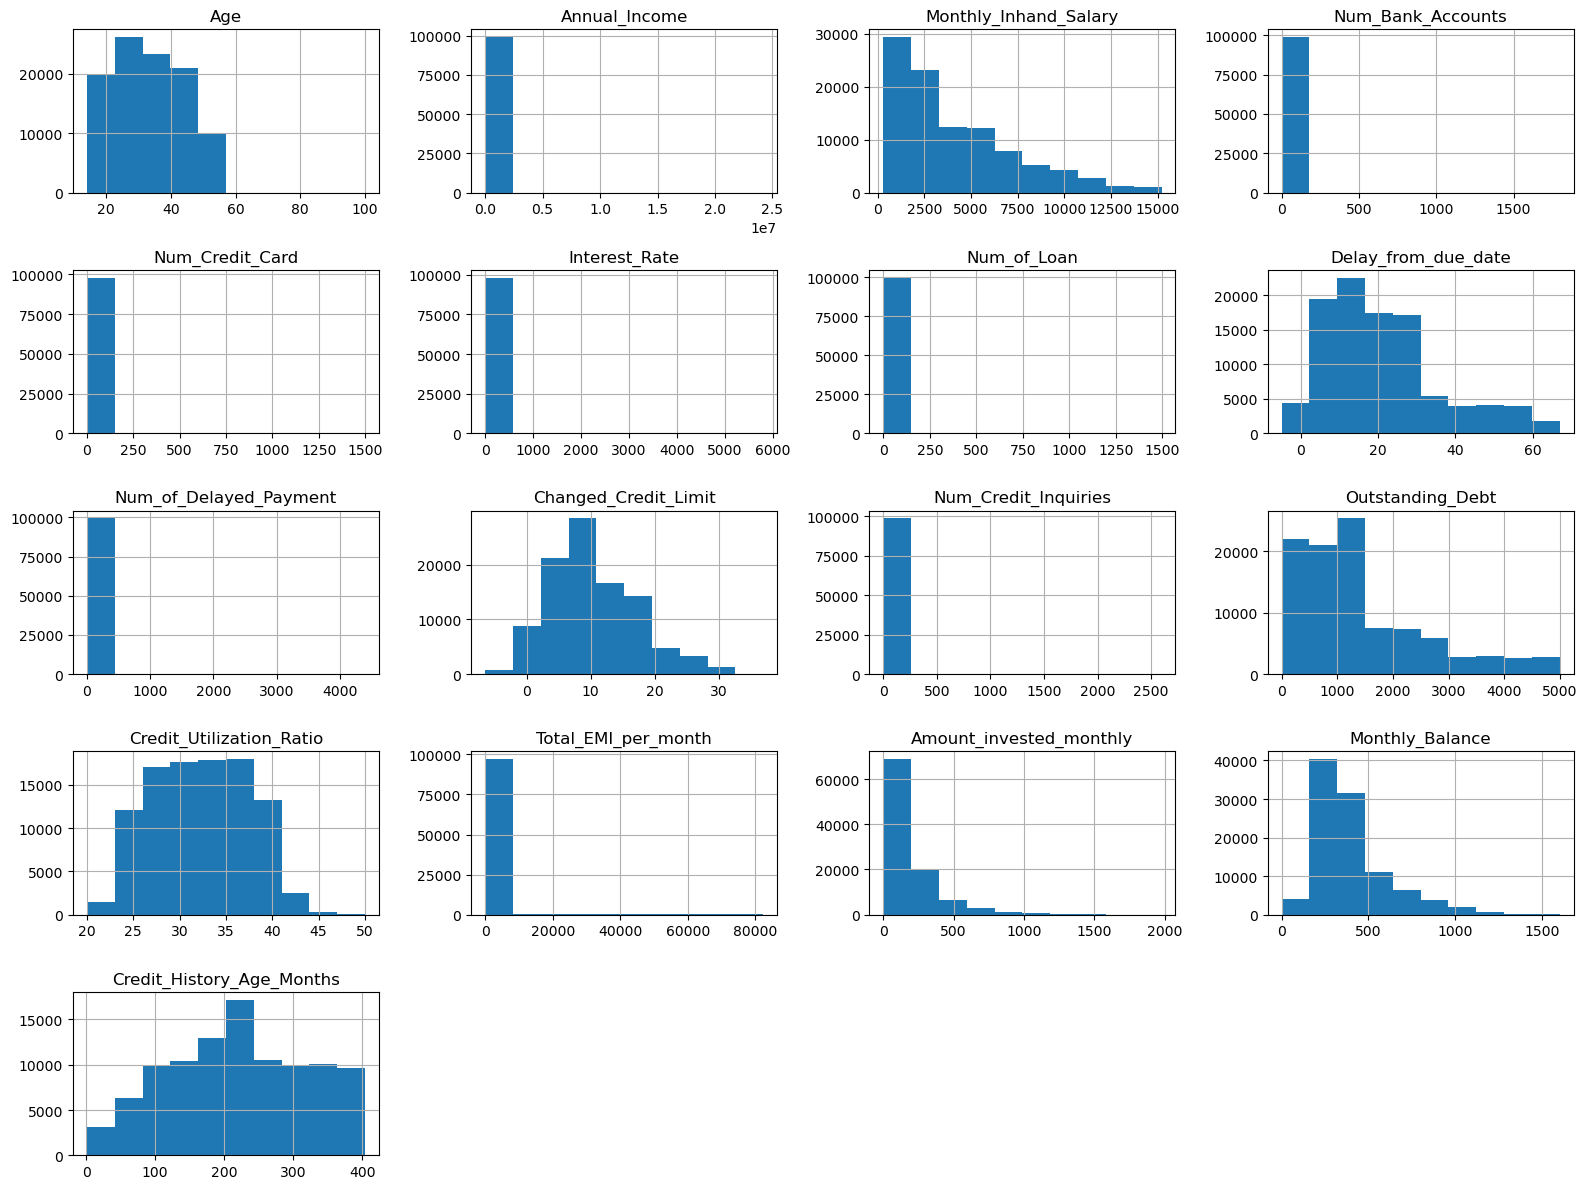

In [22]:
import matplotlib.pyplot as plt
data.hist(figsize=(16, 12))   # tăng kích thước tổng của hình
plt.tight_layout()  
plt.show()

In [24]:
numeric_cols = data.select_dtypes(include=['number'])
summary = pd.DataFrame({
    'Max': numeric_cols.max(),
    'Min': numeric_cols.min(),
    'Mean': numeric_cols.mean()
})    

In [25]:
summary

,Max,Min,Mean
Age,1.000000e+02,14.000000,33.312380
Annual_Income,2.419806e+07,7005.930000,176415.701298
Monthly_Inhand_Salary,1.520463e+04,303.645417,4198.771619
Num_Bank_Accounts,1.798000e+03,-1.000000,17.091280
Num_Credit_Card,1.499000e+03,0.000000,22.474430
Interest_Rate,5.797000e+03,1.000000,72.466040
Num_of_Loan,1.496000e+03,0.000000,7.022880
Delay_from_due_date,6.700000e+01,-5.000000,21.068780
Num_of_Delayed_Payment,4.397000e+03,0.000000,29.709680
Changed_Credit_Limit,3.697000e+01,-6.490000,10.389113


# 2. Tiền xử lý dữ liệu và trực quan hóa

# a. Kiểm tra các thuộc tính của dữ liệu, xem xét bỏ những cột không có ý nghĩa dự đoán (như tên,...). Giải thích tại sao các cột này cần xóa.

### Các loại dữ liệu nên bỏ
|Feature|Lí do|
|---|---|
|ID|	Chỉ là mã định danh dòng, không mang thông tin gì để dự đoán|
|Customer_ID|	Định danh khách hàng, không phải đặc trưng tài chính|
|Name|	Tên riêng, không liên quan đến điểm tín dụng|
|SSN|	Số định danh cá nhân, không có ý nghĩa dự đoán, còn rủi ro về dữ liệu nhạy cảm|
|Month|	Thường không ảnh hưởng nhiều đến điểm tín dụng (trừ khi bạn phân tích xu hướng theo thời gian)|
|Type_of_Loan|	Dạng text tự do, nhiều loại kết hợp phức tạp (vd "Auto Loan, Credit-Builder..."), khó dùng trực tiếp — nếu muốn giữ thì phải tách thành các cột nhị phân (one-hot) cho từng loại vay |

### Các loại dữ liệu nên giữ lại
|Nhóm|	Cột|
|---|---|
|Thông tin độ tuổi|	Age, Occupation|
|Thu nhập|	Annual_Income, Monthly_Inhand_Salary|
|Tài khoản/thẻ|	Num_Bank_Accounts, Num_Credit_Card, Interest_Rate|
|Vay nợ|	Num_of_Loan, Outstanding_Debt, Total_EMI_per_month|
|Lịch sử thanh toán|	Delay_from_due_date, Num_of_Delayed_Payment, Payment_of_Min_Amount, Payment_Behaviour|
|Tín dụng|	Changed_Credit_Limit, Num_Credit_Inquiries, Credit_Mix, Credit_Utilization_Ratio, Credit_History_Age_Months|
|Tài chính khác|	Amount_invested_monthly, Monthly_Balance|

# b. Tìm giải pháp chuyển hết các thuộc  tính về dạng số. Mô tả rõ giải pháp làm.  

- Chuyển các dữ liệu về dạng số để có thể dựa vào đó đánh gá các dữ liệu dạng `categorical`

In [27]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

def prepare_features(df):
    """
    Giữ lại các feature cần thiết cho việc dự đoán Credit_Score
    và encode các cột categorical thành dạng số.

    Input:
        df: DataFrame đã được làm sạch (D3-CreditScore-cleaned.csv)

    Output:
        X: DataFrame chỉ chứa các feature đã encode (sẵn sàng đưa vào model)
        y: Series chứa biến mục tiêu Credit_Score (dạng số)
        encoders: dict lưu lại các LabelEncoder đã dùng (để decode lại sau này nếu cần)
    """

    # ===== 1. Chọn các cột cần giữ =====
    keep_cols = [
        'Age', 'Occupation',
        'Annual_Income', 'Monthly_Inhand_Salary',
        'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate',
        'Num_of_Loan', 'Outstanding_Debt', 'Total_EMI_per_month',
        'Delay_from_due_date', 'Num_of_Delayed_Payment',
        'Payment_of_Min_Amount', 'Payment_Behaviour',
        'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix',
        'Credit_Utilization_Ratio', 'Credit_History_Age_Months',
        'Amount_invested_monthly', 'Monthly_Balance',
        'Credit_Score'  # target - sẽ tách riêng ra sau
    ]
    df = df[keep_cols].copy()

    # ===== 2. Encode các cột categorical =====
    encoders = {}

    # --- Occupation: nhiều nhóm không có thứ tự -> Label Encoding (hoặc one-hot nếu muốn) ---
    le_occ = LabelEncoder()
    df['Occupation'] = le_occ.fit_transform(df['Occupation'].astype(str))
    encoders['Occupation'] = le_occ

    # --- Payment_of_Min_Amount: Yes/No/Unknown -> map thủ công (có ý nghĩa thứ tự nhị phân) ---
    payment_map = {'No': 0, 'Yes': 1, 'Unknown': -1}
    df['Payment_of_Min_Amount'] = df['Payment_of_Min_Amount'].map(payment_map).fillna(-1).astype(int)

    # --- Payment_Behaviour: không có thứ tự rõ ràng -> Label Encoding ---
    le_pb = LabelEncoder()
    df['Payment_Behaviour'] = le_pb.fit_transform(df['Payment_Behaviour'].astype(str))
    encoders['Payment_Behaviour'] = le_pb

    # --- Credit_Mix: CÓ thứ tự tự nhiên (Bad < Standard < Good) -> map thủ công theo thứ tự ---
    credit_mix_map = {'Bad': 0, 'Standard': 1, 'Good': 2, 'Unknown': -1}
    df['Credit_Mix'] = df['Credit_Mix'].map(credit_mix_map).fillna(-1).astype(int)

    # --- Credit_Score (target): CÓ thứ tự tự nhiên (Poor < Standard < Good) ---
    score_map = {'Poor': 0, 'Standard': 1, 'Good': 2}
    df['Credit_Score'] = df['Credit_Score'].map(score_map)

    # ===== 3. Tách X và y =====
    y = df['Credit_Score']
    X = df.drop(columns=['Credit_Score'])

    return X, y, encoders

- Occupation: nhiều nhóm không có thứ tự -> Label Encoding
- Payment_of_Min_Amount: Yes/No/Unknown -> map thủ công (có ý nghĩa thứ tự nhị phân)
- Payment_Behaviour: không có thứ tự rõ ràng -> Label Encoding
- Credit_Mix: CÓ thứ tự tự nhiên (Bad < Standard < Good) -> map thủ công theo thứ tự
- Credit_Score (target): CÓ thứ tự tự nhiên (Poor < Standard < Good)

In [28]:
X, y, encoders = prepare_features(data)

print("Shape X:", X.shape)
print("Shape y:", y.shape)
print()
print(X.dtypes)
print()
print(X.head())
print()
print("Phân bố target y:")
print(y.value_counts())

Shape X: (100000, 21)
Shape y: (100000,)

Age                          float64
Occupation                     int64
Annual_Income                float64
Monthly_Inhand_Salary        float64
Num_Bank_Accounts              int64
Num_Credit_Card                int64
Interest_Rate                  int64
Num_of_Loan                  float64
Outstanding_Debt             float64
Total_EMI_per_month          float64
Delay_from_due_date            int64
Num_of_Delayed_Payment       float64
Payment_of_Min_Amount          int64
Payment_Behaviour              int64
Changed_Credit_Limit         float64
Num_Credit_Inquiries         float64
Credit_Mix                     int64
Credit_Utilization_Ratio     float64
Credit_History_Age_Months    float64
Amount_invested_monthly      float64
Monthly_Balance              float64
dtype: object

    Age  Occupation  ...  Amount_invested_monthly  Monthly_Balance
0  23.0          12  ...                80.415295       312.494089
1  23.0          12  ...        

Tỉ lệ phương sai giữ được của 2 thành phần: [0.2118008  0.08018848]
Tổng phương sai giữ được: 0.2919892802496876


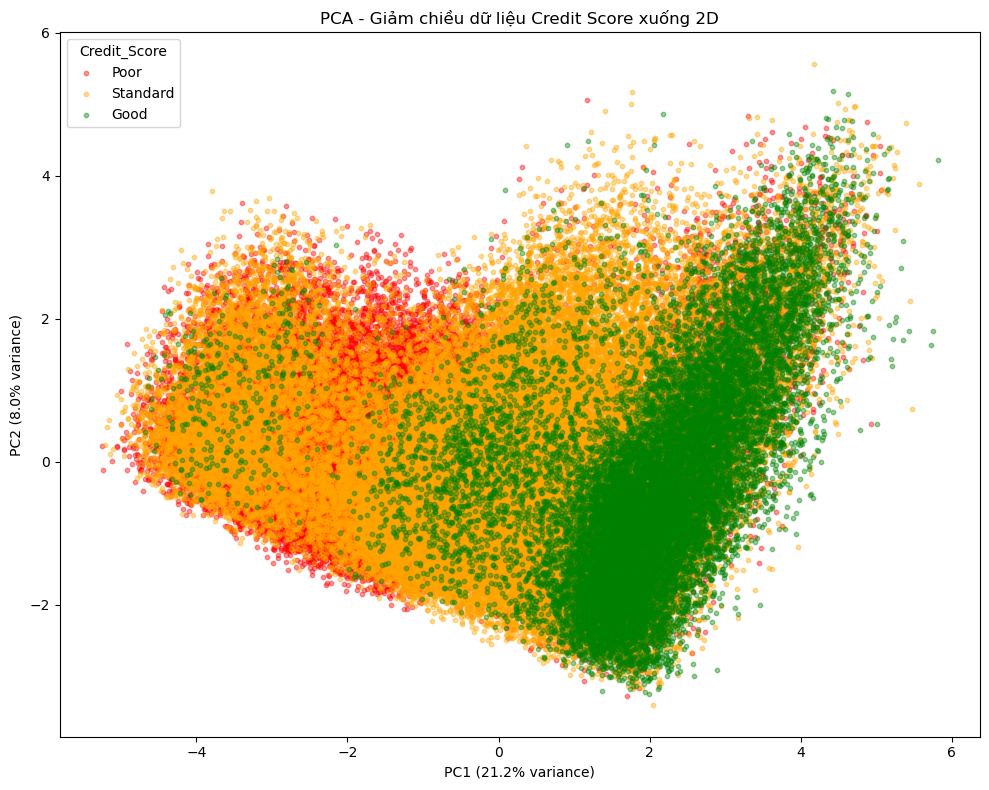

Đã lưu hình vào pca_2d.png


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ===== 2. Chuẩn hóa dữ liệu (PCA rất nhạy với scale) =====
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ===== 3. Giảm chiều xuống 2D bằng PCA =====
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Tỉ lệ phương sai giữ được của 2 thành phần:", pca.explained_variance_ratio_)
print("Tổng phương sai giữ được:", pca.explained_variance_ratio_.sum())

# ===== 4. Vẽ scatter plot 2D, mỗi nhãn 1 màu =====
label_names = {0: 'Poor', 1: 'Standard', 2: 'Good'}
colors = {0: 'red', 1: 'orange', 2: 'green'}

plt.figure(figsize=(10, 8))
for label_value, label_name in label_names.items():
    mask = (y == label_value)
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=colors[label_value],
        label=label_name,
        alpha=0.4,
        s=10
    )

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA - Giảm chiều dữ liệu Credit Score xuống 2D")
plt.legend(title="Credit_Score")
plt.tight_layout()
plt.savefig("pca_2d.png", dpi=150)
plt.show()
print("Đã lưu hình vào pca_2d.png")

In [33]:
import pandas as pd
import numpy as np
import time
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                       GridSearchCV, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

RANDOM_STATE = 42

# ===== 1. Load & chuẩn bị dữ liệu =====

X_sub, _, y_sub, _ = train_test_split(
    X, y, train_size=10000, stratify=y, random_state=RANDOM_STATE
)
print("Kích thước tập dùng để huấn luyện/so sánh:", X_sub.shape)
print("Phân bố nhãn:\n", y_sub.value_counts(normalize=True))

# ===== 2. Chuẩn hóa dữ liệu (cần cho KNN, SVM; không hại RF/AdaBoost) =====
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sub)

# ===== 3. Chọn 3 mô hình: Random Forest, AdaBoost, KNN =====
# (Bỏ SVM vì quá chậm với dữ liệu lớn - O(n^2) đến O(n^3); Naive Bayes cho baseline yếu hơn
#  do giả định các feature độc lập, không phù hợp với dữ liệu tài chính có tương quan cao)

param_grids = {
    "KNN": {
        "estimator": KNeighborsClassifier(),
        "params": {
            "n_neighbors": [5, 11, 21],
            "weights": ["uniform", "distance"],
        }
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        "params": {
            "n_estimators": [100, 200],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5],
        }
    },
    "AdaBoost": {
        "estimator": AdaBoostClassifier(random_state=RANDOM_STATE),
        "params": {
            "n_estimators": [50, 100, 200],
            "learning_rate": [0.1, 0.5, 1.0],
        }
    },
}

best_models = {}
tuning_report = {}

for name, cfg in param_grids.items():
    t0 = time.time()
    grid = GridSearchCV(
        cfg["estimator"], cfg["params"],
        cv=5, scoring="f1_macro", n_jobs=1
    )
    grid.fit(X_scaled, y_sub)
    elapsed = time.time() - t0
    best_models[name] = grid.best_estimator_
    tuning_report[name] = {
        "best_params": grid.best_params_,
        "best_cv_f1_macro": grid.best_score_,
        "tuning_time_sec": round(elapsed, 1)
    }
    print(f"[{name}] best_params={grid.best_params_}  "
          f"f1_macro={grid.best_score_:.4f}  time={elapsed:.1f}s")


Kích thước tập dùng để huấn luyện/so sánh: (10000, 21)
Phân bố nhãn:
 Credit_Score
1    0.5317
0    0.2900
2    0.1783
Name: proportion, dtype: float64
[KNN] best_params={'n_neighbors': 21, 'weights': 'distance'}  f1_macro=0.6051  time=1.4s


KeyboardInterrupt: 

In [34]:
!pwd

/mnt/datassd/CodeHub/Science/WILD/DataMining/Exam
